# Análisis de sentimiento financiero con modelos preentrenados de Hugging Face

**Gestión de Proyectos de Inteligencia Artificial — Actividad 4**

**Caso de uso:** clasificar tweets de noticias financieras como **Bearish**, **Bullish** o
**Neutral** para emitir alertas tempranas de mercado. **Rama:** NLP, clasificación de texto.

| Umbral de negocio | Accuracy ≥ 0.85 | F1 macro ≥ 0.80 | Recall Bearish ≥ 0.80 | Latencia p95 ≤ 50 ms |
|---|---|---|---|---|

El análisis completo está en `docs/reporte_tecnico_comparativo.docx`. En Colab: GPU T4 y secret `HF_TOKEN`.

## 1. Configuración de GPU

Prioridad: CUDA → MPS → CPU.

In [1]:
import os
import sys
import subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

try:
    from dotenv import load_dotenv
    load_dotenv((Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / ".env")
except ImportError:
    pass
print(f"Entorno: {'Google Colab' if IN_COLAB else 'Jupyter local'} | Python {sys.version.split()[0]}")

try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=True).stdout)
except (FileNotFoundError, subprocess.CalledProcessError):
    print("nvidia-smi no disponible.")


Entorno: Jupyter local | Python 3.13.16
nvidia-smi no disponible.


In [2]:
import os
import platform
import random
import subprocess

import numpy as np
import torch


def get_device(prefer: str | None = None) -> torch.device:
    forced = prefer or os.environ.get("FORCE_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available() and torch.backends.mps.is_built():
        return torch.device("mps")
    return torch.device("cpu")


def inference_dtype(device: torch.device) -> torch.dtype:
    return torch.float16 if device.type == "cuda" else torch.float32


def synchronize(device: torch.device) -> None:
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def reset_peak_memory(device: torch.device) -> None:
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    elif device.type == "mps":
        torch.mps.empty_cache()


def allocated_memory_mb(device: torch.device) -> float | None:
    if device.type == "cuda":
        return torch.cuda.max_memory_allocated() / 2**20
    if device.type == "mps":
        return torch.mps.driver_allocated_memory() / 2**20
    return None


def release_memory(device: torch.device) -> None:
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps":
        torch.mps.empty_cache()


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _apple_chip_name() -> str | None:
    try:
        return subprocess.run(
            ["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True, check=True
        ).stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        return None


def _total_ram_gb() -> float | None:
    try:
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
    except (ValueError, OSError, AttributeError):
        return None


def describe_hardware(device: torch.device) -> dict:
    info = {
        "device": device.type,
        "platform": platform.platform(),
        "python": platform.python_version(),
        "torch": torch.__version__,
        "cpu": _apple_chip_name() if platform.system() == "Darwin" else platform.processor(),
        "ram_gb": round(_total_ram_gb() or 0, 1),
        "accelerator": None,
        "accelerator_memory_gb": None,
        "inference_dtype": str(inference_dtype(device)).replace("torch.", ""),
    }
    if device.type == "cuda":
        props = torch.cuda.get_device_properties(0)
        info["accelerator"] = props.name
        info["accelerator_memory_gb"] = round(props.total_memory / 2**30, 1)
    elif device.type == "mps":
        info["accelerator"] = f"{info['cpu']} GPU (Metal / MPS)"
        info["accelerator_memory_gb"] = info["ram_gb"]
    else:
        info["accelerator"] = "CPU only"
    return info


In [3]:
DEVICE = get_device()
HARDWARE = describe_hardware(DEVICE)
for field, value in HARDWARE.items():
    print(f"{field:>22}: {value}")


                device: mps
              platform: macOS-27.0.1-arm64-arm-64bit-Mach-O
                python: 3.13.16
                 torch: 2.14.1
                   cpu: Apple M1 Max
                ram_gb: 32.0
           accelerator: Apple M1 Max GPU (Metal / MPS)
 accelerator_memory_gb: 32.0
       inference_dtype: float32


## 2. Instalación de dependencias

In [4]:
PACKAGES = ["transformers>=4.56", "datasets>=3.0", "evaluate>=0.4", "accelerate>=0.33",
            "huggingface_hub>=0.34", "scikit-learn>=1.3", "python-dotenv>=1.0", "openpyxl>=3.1"]
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", *PACKAGES], check=True)

import datasets, evaluate, huggingface_hub, sklearn, torch, transformers
for module in (torch, transformers, datasets, evaluate, huggingface_hub, sklearn):
    print(f"{module.__name__:>16}: {module.__version__}")


           torch: 2.14.1
    transformers: 5.19.0
        datasets: 5.1.0
        evaluate: 0.4.6
 huggingface_hub: 2.2.0
         sklearn: 1.9.1


## 3. Configuración del experimento

In [5]:
from dataclasses import dataclass
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

try:
    from dotenv import load_dotenv

    load_dotenv(PROJECT_ROOT / ".env")
except ImportError:
    pass

DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"

DATASET_CSV = DATA_DIR / "twitter_financial_news_sentiment.csv"
DATASET_XLSX = DATA_DIR / "twitter_financial_news_sentiment.xlsx"
DATASET_METADATA = DATA_DIR / "dataset_metadata.json"

DATASET_ID = "zeroshot/twitter-financial-news-sentiment"
DATASET_REVISION = "ccbe24de388e287beb92dd393a335c376b350ac3"
TRAIN_SPLIT = "train"
EVAL_SPLIT = "validation"

LABELS = ["Bearish", "Bullish", "Neutral"]
ID2LABEL = dict(enumerate(LABELS))
LABEL2ID = {name: idx for idx, name in ID2LABEL.items()}

LABEL_SYNONYMS = {
    "bearish": "Bearish",
    "negative": "Bearish",
    "bullish": "Bullish",
    "positive": "Bullish",
    "neutral": "Neutral",
}

SEED = 42
MAX_LENGTH = 128
BATCH_SIZE = 32
LATENCY_SAMPLES = 200
CPU_LATENCY_SAMPLES = 100
WARMUP_STEPS = 10


@dataclass(frozen=True)
class ModelSpec:

    key: str
    model_id: str
    revision: str
    display_name: str
    architecture: str
    training_data: str
    license: str
    in_domain: bool
    contaminated: bool = False
    legacy_classes: tuple[str, str] | None = None


MODELS = [
    ModelSpec(
        key="finbert",
        model_id="ProsusAI/finbert",
        revision="4556d13015211d73dccd3fdd39d39232506f3e43",
        display_name="FinBERT (ProsusAI)",
        architecture="BERT-base",
        training_data="Financial PhraseBank",
        license="No declarada en el Hub",
        in_domain=False,
    ),
    ModelSpec(
        key="finbert_tone",
        model_id="yiyanghkust/finbert-tone",
        revision="4921590d3c0c3832c0efea24c8381ce0bda7844b",
        display_name="FinBERT-tone",
        architecture="BERT-base",
        training_data="Reportes de analistas",
        license="No declarada en el Hub",
        in_domain=False,
        legacy_classes=("BertForSequenceClassification", "BertTokenizerFast"),
    ),
    ModelSpec(
        key="distilroberta_fin",
        model_id="mrm8488/distilroberta-finetuned-financial-news-sentiment-analysis",
        revision="ae0eab9ad336d7d548e0efe394b07c04bcaf6e91",
        display_name="DistilRoBERTa financiero",
        architecture="DistilRoBERTa",
        training_data="Financial PhraseBank",
        license="Apache-2.0",
        in_domain=False,
    ),
    ModelSpec(
        key="finbert_fintwitter",
        model_id="nickmuchi/finbert-tone-finetuned-fintwitter-classification",
        revision="551162e0b12cf19cc1f8d3d21611a9876ca620ae",
        display_name="FinBERT-tone + FinTwitter",
        architecture="BERT-base",
        training_data="zeroshot/twitter-financial-news-sentiment (train)",
        license="No declarada en el Hub",
        in_domain=True,
    ),
    ModelSpec(
        key="fintwitbert",
        model_id="StephanAkkerman/FinTwitBERT-sentiment",
        revision="da059da3b3bbcb43f9ed1aeb5ae61644010c7e1e",
        display_name="FinTwitBERT-sentiment",
        architecture="BERT-base",
        training_data="TimKoornstra/financial-tweets-sentiment",
        license="MIT",
        in_domain=True,
        contaminated=True,
    ),
]

MODELS_BY_KEY = {spec.key: spec for spec in MODELS}

BASELINE_KEY = "tfidf_logreg"
BASELINE_DISPLAY_NAME = "Baseline TF-IDF + LogReg"

THRESHOLDS = {
    "accuracy": 0.85,
    "f1_macro": 0.80,
    "recall_Bearish": 0.80,
    "p95_latency_ms": 50.0,
}


In [6]:
import pandas as pd
pd.set_option("display.max_colwidth", 80)

pd.DataFrame([{
    "modelo": s.model_id, "arquitectura": s.architecture, "datos de ajuste": s.training_data,
    "licencia": s.license, "dominio tweets": s.in_domain, "contaminado": s.contaminated,
} for s in MODELS])


,modelo,arquitectura,datos de ajuste,licencia,dominio tweets,contaminado
0,ProsusAI/finbert,BERT-base,Financial PhraseBank,No declarada en el Hub,False,False
1,yiyanghkust/finbert-tone,BERT-base,Reportes de analistas,No declarada en el Hub,False,False
2,mrm8488/distilroberta-finetuned-financial-news-sentiment-analysis,DistilRoBERTa,Financial PhraseBank,Apache-2.0,False,False
3,nickmuchi/finbert-tone-finetuned-fintwitter-classification,BERT-base,zeroshot/twitter-financial-news-sentiment (train),No declarada en el Hub,True,False
4,StephanAkkerman/FinTwitBERT-sentiment,BERT-base,TimKoornstra/financial-tweets-sentiment,MIT,True,True


## 4. Autenticación en Hugging Face Hub

Token fine-grained de solo lectura, leído del secret `HF_TOKEN` de Colab o de `.env`.

In [7]:
import os

from huggingface_hub import get_token, whoami


def _token_from_colab() -> str | None:
    try:
        from google.colab import userdata
    except ImportError:
        return None
    try:
        return userdata.get("HF_TOKEN")
    except Exception:
        return None


def _token_from_env() -> str | None:
    env_file = PROJECT_ROOT / ".env"
    if env_file.exists():
        try:
            from dotenv import load_dotenv
            load_dotenv(env_file)
        except ImportError:
            pass
    return os.environ.get("HF_TOKEN")


def authenticate(verbose: bool = True) -> str | None:
    token = _token_from_colab() or _token_from_env() or get_token()
    if not token:
        if verbose:
            print("Sin token de Hugging Face: modo anónimo.")
        return None
    os.environ["HF_TOKEN"] = token
    if verbose:
        print(f"Autenticado en Hugging Face Hub como {whoami(token=token)['name']}.")
    return token


In [8]:
HF_TOKEN = authenticate()


Autenticado en Hugging Face Hub como MoisesCordova.


## 5. Carga del dataset

[`zeroshot/twitter-financial-news-sentiment`](https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment). `validation` es el conjunto de prueba.

In [9]:
import re

import pandas as pd
from datasets import DatasetDict, load_dataset


URL_PATTERN = re.compile(r"https?://\S+")
CASHTAG_PATTERN = re.compile(r"\$[A-Za-z][A-Za-z.]{0,9}\b")
WHITESPACE_PATTERN = re.compile(r"\s+")


def load_splits(token: str | None = None) -> DatasetDict:
    return load_dataset(DATASET_ID, revision=DATASET_REVISION, token=token)


def clean_tweet(text: str) -> str:
    return WHITESPACE_PATTERN.sub(" ", URL_PATTERN.sub(" ", text)).strip()


def to_dataframe(splits: DatasetDict) -> pd.DataFrame:
    frames = []
    for split_name, split in splits.items():
        frame = split.to_pandas()
        frame.insert(0, "split", split_name)
        frame.insert(0, "id", [f"{split_name}-{i:05d}" for i in range(len(frame))])
        frames.append(frame)
    df = pd.concat(frames, ignore_index=True)
    df["label_name"] = df["label"].map(ID2LABEL)
    df["text_clean"] = df["text"].map(clean_tweet)
    df["n_chars"] = df["text"].str.len()
    df["n_words"] = df["text"].str.split().str.len()
    df["has_url"] = df["text"].str.contains(URL_PATTERN)
    df["n_cashtags"] = df["text"].str.count(CASHTAG_PATTERN)
    return df[
        ["id", "split", "text", "text_clean", "label", "label_name",
         "n_chars", "n_words", "has_url", "n_cashtags"]
    ]


In [10]:
splits = load_splits(HF_TOKEN)
df = to_dataframe(splits)
train_df = df[df["split"] == TRAIN_SPLIT].reset_index(drop=True)
eval_df = df[df["split"] == EVAL_SPLIT].reset_index(drop=True)
print(f"Entrenamiento: {len(train_df):,} | Evaluación: {len(eval_df):,}")
eval_df[["id", "text", "text_clean", "label_name"]].head()


Entrenamiento: 9,543 | Evaluación: 2,388


,id,text,text_clean,label_name
0,validation-00000,$ALLY - Ally Financial pulls outlook https://t.co/G9Zdi1boy5,$ALLY - Ally Financial pulls outlook,Bearish
1,validation-00001,"$DELL $HPE - Dell, HPE targets trimmed on compute headwinds https://t.co/YRU...","$DELL $HPE - Dell, HPE targets trimmed on compute headwinds",Bearish
2,validation-00002,$PRTY - Moody's turns negative on Party City https://t.co/MBD5TFGC4P,$PRTY - Moody's turns negative on Party City,Bearish
3,validation-00003,$SAN: Deutsche Bank cuts to Hold,$SAN: Deutsche Bank cuts to Hold,Bearish
4,validation-00004,$SITC: Compass Point cuts to Sell,$SITC: Compass Point cuts to Sell,Bearish


In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap


SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
MUTED = "#8a8984"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SURFACE = "#fcfcfb"
GRID = "#e4e3df"
SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "font.size": 10,
    "legend.frameon": False,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
})


def _save(fig: plt.Figure, name: str) -> Path:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURES_DIR / name
    fig.savefig(path)
    return path


def _short_name(row: pd.Series) -> str:
    return f"{row['modelo']} ⚠" if row["contaminado"] else row["modelo"]


def plot_class_distribution(df: pd.DataFrame) -> plt.Figure:
    shares = (
        df.groupby("split")["label_name"].value_counts(normalize=True)
        .unstack().reindex(columns=LABELS).mul(100)
    )
    fig, ax = plt.subplots(figsize=(7, 3.2))
    y = np.arange(len(LABELS))
    height = 0.38
    for i, split in enumerate(["train", "validation"]):
        values = shares.loc[split].values
        bars = ax.barh(y + (i - 0.5) * (height + 0.02), values, height=height, color=SERIES[i],
                       label="Entrenamiento" if split == "train" else "Validación")
        ax.bar_label(bars, labels=[f"{v:.1f} %" for v in values], padding=4, color=TEXT_SECONDARY, fontsize=9)
    ax.set_yticks(y, LABELS)
    ax.invert_yaxis()
    ax.set_xlabel("% de tweets")
    ax.set_xlim(0, 80)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_title("Distribución de clases por partición")
    ax.legend(loc="upper right")
    _save(fig, "class_distribution.png")
    return fig


def plot_metric_comparison(comparison: pd.DataFrame) -> plt.Figure:
    data = comparison.sort_values("f1_macro")
    names = [_short_name(row) for _, row in data.iterrows()]
    y = np.arange(len(data))
    height = 0.38
    fig, ax = plt.subplots(figsize=(8, 0.62 * len(data) + 1.4))
    for i, (metric, label) in enumerate([("accuracy", "Accuracy"), ("f1_macro", "F1 macro")]):
        values = data[metric].values
        bars = ax.barh(y + (i - 0.5) * (height + 0.02), values, height=height, color=SERIES[i], label=label)
        ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=3, color=TEXT_SECONDARY, fontsize=8.5)
    for metric, color, label in [("accuracy", SERIES[0], "Umbral accuracy"), ("f1_macro", SERIES[1], "Umbral F1 macro")]:
        ax.axvline(THRESHOLDS[metric], color=color, linestyle="--", linewidth=1.2,
                   label=f"{label} ({THRESHOLDS[metric]:.2f})")
    ax.set_yticks(y, names)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel("Puntaje")
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_title("Calidad por modelo")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4)
    _save(fig, "metric_comparison.png")
    return fig


def plot_tradeoff(comparison: pd.DataFrame) -> plt.Figure:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
    panels = [("accel_p95_ms", "Latencia p95 GPU (ms)"), ("cpu_p95_ms", "Latencia p95 CPU (ms)")]
    for ax, (column, xlabel) in zip(axes, panels):
        for _, row in comparison.iterrows():
            x, y = row[column], row["f1_macro"]
            if np.isnan(x):
                continue
            if row["contaminado"]:
                ax.scatter(x, y, s=70, facecolors="none", edgecolors=MUTED, linewidths=2, zorder=3)
            elif row["key"] == "tfidf_logreg":
                ax.scatter(x, y, s=70, marker="s", color=SERIES[1], edgecolors=SURFACE, linewidths=2, zorder=3)
            else:
                ax.scatter(x, y, s=70, color=SERIES[0], edgecolors=SURFACE, linewidths=2, zorder=3)
            offset = (7, -13) if row["contaminado"] else (7, 4)
            ax.annotate(_short_name(row), (x, y), xytext=offset, textcoords="offset points",
                        fontsize=8.5, color=TEXT_PRIMARY)
        ax.axhline(THRESHOLDS["f1_macro"], color=TEXT_SECONDARY, linestyle="--", linewidth=1)
        if column == "accel_p95_ms":
            ax.axvline(THRESHOLDS["p95_latency_ms"], color=TEXT_SECONDARY, linestyle=":", linewidth=1)
            ax.text(THRESHOLDS["p95_latency_ms"], 0.02, " límite 50 ms", transform=ax.get_xaxis_transform(),
                    color=TEXT_SECONDARY, fontsize=8)
        ax.set_xscale("log")
        ax.set_xlabel(xlabel)
        ax.grid(color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("F1 macro")
    axes[0].text(0.01, THRESHOLDS["f1_macro"], " umbral F1 0.80", transform=axes[0].get_yaxis_transform(),
                 color=TEXT_SECONDARY, fontsize=8, va="bottom")
    fig.suptitle("Trade-off eficiencia vs. precisión",
                 color=TEXT_PRIMARY, fontweight="bold")
    handles = [
        plt.Line2D([], [], marker="o", linestyle="", color=SERIES[0], markersize=8, label="Transformer de HF"),
        plt.Line2D([], [], marker="s", linestyle="", color=SERIES[1], markersize=8, label="Baseline clásico"),
        plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="none", markeredgecolor=MUTED,
                   markeredgewidth=2, markersize=8, label="Contaminado"),
    ]
    fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
    _save(fig, "tradeoff_latency_f1.png")
    return fig


def plot_confusion_matrices(results: list[dict], primary_text: str) -> plt.Figure:
    n = len(results)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.6 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, res in zip(axes, results):
        counts = np.array(res["variants"][primary_text]["confusion"])
        shares = counts / counts.sum(axis=1, keepdims=True)
        ax.imshow(shares, cmap=SEQUENTIAL_BLUE, vmin=0, vmax=1)
        for i in range(len(LABELS)):
            for j in range(len(LABELS)):
                color = SURFACE if shares[i, j] > 0.55 else TEXT_PRIMARY
                ax.text(j, i, f"{shares[i, j]:.0%}\n({counts[i, j]})", ha="center", va="center",
                        fontsize=8.5, color=color)
        ax.set_xticks(range(len(LABELS)), LABELS, fontsize=8.5)
        ax.set_yticks(range(len(LABELS)), LABELS, fontsize=8.5)
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Real")
        ax.set_title(res["display_name"], fontsize=10)
        ax.spines[:].set_visible(False)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Matrices de confusión normalizadas por fila",
                 color=TEXT_PRIMARY, fontweight="bold")
    fig.tight_layout()
    _save(fig, "confusion_matrices.png")
    return fig


label_name,Bearish,Bullish,Neutral,Total
split,,,,
train,1442,1923,6178,9543
validation,347,475,1566,2388


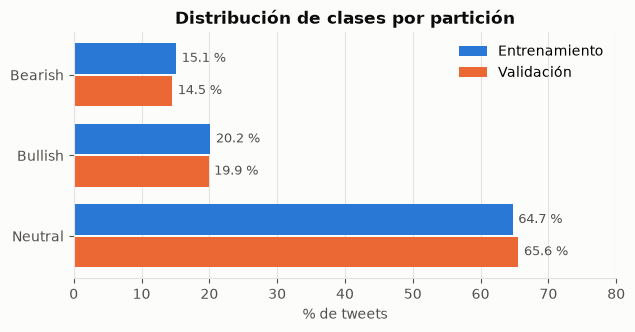

In [12]:
distribution = df.groupby(["split", "label_name"]).size().unstack().reindex(columns=LABELS)
display(distribution.assign(Total=distribution.sum(axis=1)))
plot_class_distribution(df);


Neutral concentra ~65 % de los tweets: la comparación prioriza **F1 macro** y **recall Bearish**.

## 6. Pipeline de inferencia

Ajustes mínimos: mapeo de etiquetas, limpieza de URLs y truncado a 128 tokens.

In [13]:
import time
from collections.abc import Sequence

import torch
import transformers
from transformers import Pipeline, pipeline


transformers.utils.logging.disable_progress_bar()


def load_pipeline(spec: ModelSpec, device: torch.device, token: str | None = None) -> tuple[Pipeline, float]:
    start = time.perf_counter()
    hub_kwargs = {"revision": spec.revision, "token": token}
    if spec.legacy_classes:
        model_class, tokenizer_class = (getattr(transformers, name) for name in spec.legacy_classes)
        model = model_class.from_pretrained(spec.model_id, dtype=inference_dtype(device), **hub_kwargs)
        tokenizer = tokenizer_class.from_pretrained(spec.model_id, **hub_kwargs)
        classifier = pipeline(task="text-classification", model=model, tokenizer=tokenizer, device=device)
    else:
        classifier = pipeline(
            task="text-classification",
            model=spec.model_id,
            device=device,
            dtype=inference_dtype(device),
            **hub_kwargs,
        )
    synchronize(device)
    return classifier, time.perf_counter() - start


def normalize_label(raw_label: str) -> str:
    key = raw_label.strip().lower()
    if key not in LABEL_SYNONYMS:
        raise ValueError(f"Model label {raw_label!r} has no mapping in LABEL_SYNONYMS")
    return LABEL_SYNONYMS[key]


def _top_prediction(output: dict | list) -> dict:
    return output[0] if isinstance(output, list) else output


def classify_one(classifier: Pipeline, text: str) -> dict:
    return _top_prediction(classifier(text, truncation=True, max_length=MAX_LENGTH))


def predict(
    classifier: Pipeline, texts: Sequence[str], batch_size: int = BATCH_SIZE
) -> tuple[list[str], list[float], float]:
    device = classifier.device
    synchronize(device)
    start = time.perf_counter()
    outputs = classifier(list(texts), batch_size=batch_size, truncation=True, max_length=MAX_LENGTH)
    synchronize(device)
    elapsed = time.perf_counter() - start
    top = [_top_prediction(output) for output in outputs]
    return [normalize_label(o["label"]) for o in top], [float(o["score"]) for o in top], elapsed


def model_footprint(classifier: Pipeline) -> dict:
    params = sum(p.numel() for p in classifier.model.parameters())
    weight_bytes = sum(p.numel() * p.element_size() for p in classifier.model.parameters())
    return {"params_m": params / 1e6, "weights_mb": weight_bytes / 2**20}


In [14]:
examples = [
    "$AAPL shares plunge after weak iPhone guidance https://t.co/abc123",
    "Fed holds rates steady, as widely expected",
    "Tesla beats delivery estimates; stock jumps 8% premarket",
]
demo_classifier, demo_load_s = load_pipeline(MODELS[0], DEVICE, HF_TOKEN)
for text in examples:
    raw = classify_one(demo_classifier, clean_tweet(text))
    print(f"{raw['label']:>9} → {normalize_label(raw['label']):<8} {raw['score']:.3f}  {text}")
del demo_classifier


 negative → Bearish  0.961  $AAPL shares plunge after weak iPhone guidance https://t.co/abc123
  neutral → Neutral  0.830  Fed holds rates steady, as widely expected
 positive → Bullish  0.904  Tesla beats delivery estimates; stock jumps 8% premarket


## 7. Métricas y latencia

In [15]:
from collections.abc import Sequence

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support


_EVALUATE_METRICS = None


def _load_evaluate_metrics():
    global _EVALUATE_METRICS
    if _EVALUATE_METRICS is None:
        try:
            import evaluate
            _EVALUATE_METRICS = {
                name: evaluate.load(name) for name in ("accuracy", "precision", "recall", "f1")
            }
        except Exception as error:
            print(f"No se pudo cargar evaluate, se usa scikit-learn: {error}")
            _EVALUATE_METRICS = {}
    return _EVALUATE_METRICS


def compute_metrics(y_true: Sequence[str], y_pred: Sequence[str]) -> dict:
    true_ids = np.array([LABEL2ID[label] for label in y_true])
    pred_ids = np.array([LABEL2ID[label] for label in y_pred])
    label_ids = list(range(len(LABELS)))

    precision, recall, f1, support = precision_recall_fscore_support(
        true_ids, pred_ids, labels=label_ids, zero_division=0
    )
    _, _, f1_weighted, _ = precision_recall_fscore_support(
        true_ids, pred_ids, labels=label_ids, average="weighted", zero_division=0
    )
    result = {
        "accuracy": float((true_ids == pred_ids).mean()),
        "precision_macro": float(precision.mean()),
        "recall_macro": float(recall.mean()),
        "f1_macro": float(f1.mean()),
        "f1_weighted": float(f1_weighted),
    }

    hf_metrics = _load_evaluate_metrics()
    if hf_metrics:
        hf_values = {
            "accuracy": hf_metrics["accuracy"].compute(predictions=pred_ids, references=true_ids)["accuracy"],
            "precision_macro": hf_metrics["precision"].compute(
                predictions=pred_ids, references=true_ids, average="macro", zero_division=0)["precision"],
            "recall_macro": hf_metrics["recall"].compute(
                predictions=pred_ids, references=true_ids, average="macro", zero_division=0)["recall"],
            "f1_macro": hf_metrics["f1"].compute(
                predictions=pred_ids, references=true_ids, average="macro")["f1"],
        }
        for name, value in hf_values.items():
            if not np.isclose(value, result[name]):
                raise AssertionError(f"`evaluate` and scikit-learn disagree on {name}")
        result["metrics_backend"] = "evaluate"
    else:
        result["metrics_backend"] = "scikit-learn"

    for idx, label in enumerate(LABELS):
        result[f"precision_{label}"] = float(precision[idx])
        result[f"recall_{label}"] = float(recall[idx])
        result[f"f1_{label}"] = float(f1[idx])
        result[f"support_{label}"] = int(support[idx])
    return result


def confusion(y_true: Sequence[str], y_pred: Sequence[str]) -> np.ndarray:
    return confusion_matrix(y_true, y_pred, labels=LABELS)


def threshold_checks(row: dict) -> dict:
    checks = {
        "cumple_accuracy": row["accuracy"] >= THRESHOLDS["accuracy"],
        "cumple_f1_macro": row["f1_macro"] >= THRESHOLDS["f1_macro"],
        "cumple_recall_bearish": row["recall_Bearish"] >= THRESHOLDS["recall_Bearish"],
        "cumple_latencia": row["accel_p95_ms"] <= THRESHOLDS["p95_latency_ms"],
    }
    checks["cumple_todos"] = all(checks.values())
    checks["elegible"] = checks["cumple_todos"] and not row.get("contaminado", False)
    return checks


def confidence_coverage(
    y_true: Sequence[str],
    y_pred: Sequence[str],
    scores: Sequence[float],
    cutoffs: Sequence[float] = (0.0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95),
) -> pd.DataFrame:
    y_true, y_pred, scores = np.asarray(y_true), np.asarray(y_pred), np.asarray(scores)
    rows = []
    for cutoff in cutoffs:
        covered = scores >= cutoff
        metrics = compute_metrics(y_true[covered], y_pred[covered])
        rows.append({
            "umbral_confianza": cutoff,
            "cobertura": covered.mean(),
            "a_revision_humana": int((~covered).sum()),
            "accuracy": metrics["accuracy"],
            "f1_macro": metrics["f1_macro"],
            "recall_Bearish": metrics["recall_Bearish"],
            "precision_Bearish": metrics["precision_Bearish"],
        })
    return pd.DataFrame(rows)


In [16]:
import time
from collections.abc import Callable, Sequence

import numpy as np
import torch


def latency_sample(texts: Sequence[str], size: int, seed: int = SEED) -> list[str]:
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(texts), size=min(size, len(texts)), replace=False)
    return [texts[i] for i in indices]


def measure_latency(
    predict_one: Callable[[str], object],
    texts: Sequence[str],
    device: torch.device,
    warmup: int = WARMUP_STEPS,
) -> dict:
    for text in texts[:warmup]:
        predict_one(text)
    timings_ms = []
    for text in texts:
        synchronize(device)
        start = time.perf_counter()
        predict_one(text)
        synchronize(device)
        timings_ms.append((time.perf_counter() - start) * 1000)
    timings = np.array(timings_ms)
    return {
        "mean_ms": float(timings.mean()),
        "p50_ms": float(np.percentile(timings, 50)),
        "p95_ms": float(np.percentile(timings, 95)),
        "n": len(timings),
    }


In [17]:
import gc
import json
import pickle
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline


TEXT_VARIANTS = {"text": "original", "text_clean": "sin URLs"}
PRIMARY_TEXT = "text_clean"


def evaluate_model(
    spec: ModelSpec,
    eval_df: pd.DataFrame,
    device: torch.device,
    token: str | None = None,
    measure_cpu: bool = True,
) -> dict:
    classifier, load_seconds = load_pipeline(spec, device, token)
    result = {
        "key": spec.key,
        "display_name": spec.display_name,
        "device": device.type,
        "load_s": load_seconds,
        **model_footprint(classifier),
        "variants": {},
    }
    for column in TEXT_VARIANTS:
        labels, scores, elapsed = predict(classifier, eval_df[column].tolist())
        result["variants"][column] = {
            "pred": labels,
            "score": scores,
            "elapsed_s": elapsed,
            "metrics": compute_metrics(eval_df["label_name"], labels),
            "confusion": confusion(eval_df["label_name"], labels).tolist(),
        }

    sample = latency_sample(eval_df[PRIMARY_TEXT].tolist(), LATENCY_SAMPLES)
    result["accel_latency"] = measure_latency(lambda text: classify_one(classifier, text), sample, device)
    del classifier
    gc.collect()
    release_memory(device)

    if device.type == "cpu":
        result["cpu_latency"] = result["accel_latency"]
    elif measure_cpu:
        cpu = torch.device("cpu")
        cpu_classifier, _ = load_pipeline(spec, cpu, token)
        cpu_sample = sample[:CPU_LATENCY_SAMPLES]
        result["cpu_latency"] = measure_latency(lambda text: classify_one(cpu_classifier, text), cpu_sample, cpu)
        del cpu_classifier
        gc.collect()
    else:
        result["cpu_latency"] = None
    return result


def evaluate_baseline(train_df: pd.DataFrame, eval_df: pd.DataFrame) -> dict:
    result = {"key": BASELINE_KEY, "display_name": BASELINE_DISPLAY_NAME, "device": "cpu", "variants": {}}
    model = None
    for column in TEXT_VARIANTS:
        candidate = make_pipeline(
            TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
            LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
        )
        start = time.perf_counter()
        candidate.fit(train_df[column], train_df["label_name"])
        train_seconds = time.perf_counter() - start
        start = time.perf_counter()
        labels = candidate.predict(eval_df[column]).tolist()
        elapsed = time.perf_counter() - start
        scores = candidate.predict_proba(eval_df[column]).max(axis=1).tolist()
        result["variants"][column] = {
            "pred": labels,
            "score": scores,
            "elapsed_s": elapsed,
            "metrics": compute_metrics(eval_df["label_name"], labels),
            "confusion": confusion(eval_df["label_name"], labels).tolist(),
        }
        if column == PRIMARY_TEXT:
            model, result["load_s"] = candidate, train_seconds

    classifier = model.named_steps["logisticregression"]
    result["params_m"] = classifier.coef_.size / 1e6
    result["weights_mb"] = len(pickle.dumps(model)) / 2**20
    sample = latency_sample(eval_df[PRIMARY_TEXT].tolist(), LATENCY_SAMPLES)
    cpu = torch.device("cpu")
    result["accel_latency"] = measure_latency(lambda text: model.predict([text]), sample, cpu)
    result["cpu_latency"] = result["accel_latency"]
    return result


def comparison_table(results: list[dict], specs: dict[str, ModelSpec], n_eval: int) -> pd.DataFrame:
    rows = []
    for res in results:
        variant = res["variants"][PRIMARY_TEXT]
        spec = specs.get(res["key"])
        throughput = n_eval / variant["elapsed_s"]
        row = {
            "modelo": res["display_name"],
            "key": res["key"],
            "model_id": spec.model_id if spec else "scikit-learn",
            "arquitectura": spec.architecture if spec else "TF-IDF + regresión logística",
            "licencia": spec.license if spec else "BSD-3-Clause",
            "en_dominio": spec.in_domain if spec else True,
            "contaminado": spec.contaminated if spec else False,
            "params_m": res["params_m"],
            "weights_mb": res["weights_mb"],
            "load_s": res["load_s"],
            **{k: v for k, v in variant["metrics"].items() if k != "metrics_backend"},
            "device": res["device"],
            "accel_p50_ms": res["accel_latency"]["p50_ms"],
            "accel_p95_ms": res["accel_latency"]["p95_ms"],
            "cpu_p50_ms": res["cpu_latency"]["p50_ms"] if res["cpu_latency"] else np.nan,
            "cpu_p95_ms": res["cpu_latency"]["p95_ms"] if res["cpu_latency"] else np.nan,
            "throughput_tps": throughput,
            "horas_por_millon": 1e6 / throughput / 3600,
        }
        row.update(threshold_checks(row))
        rows.append(row)
    return pd.DataFrame(rows)


def recommend(comparison: pd.DataFrame) -> pd.Series:
    clean = comparison[~comparison["contaminado"]]
    pool = clean[clean["elegible"]] if clean["elegible"].any() else clean
    return pool.sort_values(["f1_macro", "accel_p95_ms"], ascending=[False, True]).iloc[0]


def ablation_table(results: list[dict]) -> pd.DataFrame:
    rows = []
    for res in results:
        for column, variant_name in TEXT_VARIANTS.items():
            metrics = res["variants"][column]["metrics"]
            rows.append({
                "modelo": res["display_name"],
                "texto": variant_name,
                "accuracy": metrics["accuracy"],
                "f1_macro": metrics["f1_macro"],
                "recall_Bearish": metrics["recall_Bearish"],
            })
    table = pd.DataFrame(rows).pivot(index="modelo", columns="texto")
    table.columns = [f"{metric} ({variant})" for metric, variant in table.columns]
    table["delta_f1_macro"] = table["f1_macro (sin URLs)"] - table["f1_macro (original)"]
    return table.reset_index()


def per_class_table(results: list[dict]) -> pd.DataFrame:
    rows = []
    for res in results:
        metrics = res["variants"][PRIMARY_TEXT]["metrics"]
        for label in LABELS:
            rows.append({
                "modelo": res["display_name"],
                "clase": label,
                "precision": metrics[f"precision_{label}"],
                "recall": metrics[f"recall_{label}"],
                "f1": metrics[f"f1_{label}"],
                "soporte": metrics[f"support_{label}"],
            })
    return pd.DataFrame(rows)


def partial_conclusion(row: pd.Series) -> str:
    def mark(ok: bool) -> str:
        return "✔" if ok else "✘"

    lines = [
        f"{row['modelo']} — accuracy {row['accuracy']:.3f} {mark(row['cumple_accuracy'])} | "
        f"F1 macro {row['f1_macro']:.3f} {mark(row['cumple_f1_macro'])} | "
        f"recall Bearish {row['recall_Bearish']:.3f} {mark(row['cumple_recall_bearish'])} | "
        f"p95 {row['accel_p95_ms']:.1f} ms en {row['device'].upper()} {mark(row['cumple_latencia'])}",
    ]
    weakest = min(LABELS, key=lambda label: row[f"f1_{label}"])
    lines.append(f"  Clase más débil: {weakest}, F1 {row[f'f1_{weakest}']:.3f}.")
    if row["contaminado"]:
        lines.append("  ⚠ Contaminado: entrenó con el split de evaluación.")
    elif row["cumple_todos"]:
        lines.append("  Cumple todos los umbrales.")
    else:
        failed = [name for name, ok in [
            ("accuracy", row["cumple_accuracy"]), ("F1 macro", row["cumple_f1_macro"]),
            ("recall Bearish", row["cumple_recall_bearish"]), ("latencia", row["cumple_latencia"]),
        ] if not ok]
        lines.append(f"  No cumple: {', '.join(failed)}.")
    return "\n".join(lines)


def save_results(
    results: list[dict],
    comparison: pd.DataFrame,
    ablation: pd.DataFrame,
    per_class: pd.DataFrame,
    eval_df: pd.DataFrame,
    hardware: dict,
    confidence: pd.DataFrame | None = None,
) -> None:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
    comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
    if confidence is not None:
        confidence.to_csv(RESULTS_DIR / "confidence_thresholds.csv", index=False)
    ablation.to_csv(RESULTS_DIR / "ablation_text_cleaning.csv", index=False)
    per_class.to_csv(RESULTS_DIR / "per_class_metrics.csv", index=False)

    confusions = {}
    for res in results:
        variant = res["variants"][PRIMARY_TEXT]
        confusions[res["key"]] = {"labels": LABELS, "matrix": variant["confusion"]}
        pd.DataFrame({
            "id": eval_df["id"],
            "text": eval_df["text"],
            "label": eval_df["label_name"],
            "pred": variant["pred"],
            "score": variant["score"],
        }).to_csv(PREDICTIONS_DIR / f"{res['key']}.csv", index=False)
    (RESULTS_DIR / "confusion_matrices.json").write_text(json.dumps(confusions, indent=2), encoding="utf-8")

    import datasets
    import sklearn
    import transformers
    metadata = {
        "run_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "hardware": hardware,
        "libraries": {
            "transformers": transformers.__version__,
            "datasets": datasets.__version__,
            "scikit-learn": sklearn.__version__,
            "torch": torch.__version__,
        },
        "eval_rows": len(eval_df),
        "primary_text_variant": PRIMARY_TEXT,
        "recommended_model": recommend(comparison)["key"],
        "thresholds": THRESHOLDS,
        "latency_samples": {"accelerator": LATENCY_SAMPLES, "cpu": CPU_LATENCY_SAMPLES},
    }
    (RESULTS_DIR / "run_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")


In [18]:
from IPython.display import display

results = {}

def report(result: dict) -> pd.Series:
    row = comparison_table([result], MODELS_BY_KEY, len(eval_df)).iloc[0]
    columns = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "recall_Bearish",
               "accel_p50_ms", "accel_p95_ms", "cpu_p95_ms", "throughput_tps", "params_m"]
    display(row[columns].to_frame("valor").T.round(4))
    print(partial_conclusion(row))
    return row


## 8. Evaluación de cada modelo

### 8.1 Modelo 1 — `ProsusAI/finbert`

BERT-base ajustado con noticias de Financial PhraseBank; el referente más descargado del Hub.

In [19]:
results["finbert"] = evaluate_model(MODELS_BY_KEY["finbert"], eval_df, DEVICE, HF_TOKEN)
row_finbert = report(results["finbert"])


,accuracy,precision_macro,recall_macro,f1_macro,recall_Bearish,accel_p50_ms,accel_p95_ms,cpu_p95_ms,throughput_tps,params_m
valor,0.715662,0.642527,0.698762,0.659889,0.752161,9.415708,10.906402,31.692466,634.387045,109.484547


FinBERT (ProsusAI) — accuracy 0.716 ✘ | F1 macro 0.660 ✘ | recall Bearish 0.752 ✘ | p95 10.9 ms en MPS ✔
  Clase más débil: Bearish, F1 0.590.
  No cumple: accuracy, F1 macro, recall Bearish.


**Conclusión parcial.** No cumple ningún umbral de calidad: F1 macro de 0.660 y precisión Bearish de 0.49, casi la mitad de sus alertas de riesgo serían falsas. Pesa la brecha de dominio entre noticias y tweets.

### 8.2 Modelo 2 — `yiyanghkust/finbert-tone`

BERT-base ajustado con reportes de analistas; se carga con clases explícitas porque su config no declara `model_type`.

In [20]:
results["finbert_tone"] = evaluate_model(MODELS_BY_KEY["finbert_tone"], eval_df, DEVICE, HF_TOKEN)
row_finbert_tone = report(results["finbert_tone"])


,accuracy,precision_macro,recall_macro,f1_macro,recall_Bearish,accel_p50_ms,accel_p95_ms,cpu_p95_ms,throughput_tps,params_m
valor,0.741206,0.669689,0.693627,0.679895,0.648415,9.276458,10.465037,28.554983,665.187906,109.754115


FinBERT-tone — accuracy 0.741 ✘ | F1 macro 0.680 ✘ | recall Bearish 0.648 ✘ | p95 10.5 ms en MPS ✔
  Clase más débil: Bearish, F1 0.590.
  No cumple: accuracy, F1 macro, recall Bearish.


**Conclusión parcial.** Peor recall Bearish, 0.648: clasifica como Neutral el 31 % de los tweets bajistas.

### 8.3 Modelo 3 — `mrm8488/distilroberta-finetuned-financial-news-sentiment-analysis`

DistilRoBERTa de 82 M parámetros ajustado con noticias; el candidato de eficiencia.

In [21]:
results["distilroberta_fin"] = evaluate_model(MODELS_BY_KEY["distilroberta_fin"], eval_df, DEVICE, HF_TOKEN)
row_distilroberta_fin = report(results["distilroberta_fin"])


,accuracy,precision_macro,recall_macro,f1_macro,recall_Bearish,accel_p50_ms,accel_p95_ms,cpu_p95_ms,throughput_tps,params_m
valor,0.754606,0.685194,0.75117,0.709932,0.772334,5.416438,6.354641,16.46125,1161.477516,82.120707


DistilRoBERTa financiero — accuracy 0.755 ✘ | F1 macro 0.710 ✘ | recall Bearish 0.772 ✘ | p95 6.4 ms en MPS ✔
  Clase más débil: Bullish, F1 0.653.
  No cumple: accuracy, F1 macro, recall Bearish.


**Conclusión parcial.** El mejor de los modelos de noticias y el transformer más rápido, p95 ≈ 6 ms, pero su F1 macro de 0.710 queda debajo de los umbrales.

### 8.4 Modelo 4 — `nickmuchi/finbert-tone-finetuned-fintwitter-classification`

FinBERT-tone ajustado con `train` de este dataset: mismo dominio que el caso de uso.

In [22]:
results["finbert_fintwitter"] = evaluate_model(MODELS_BY_KEY["finbert_fintwitter"], eval_df, DEVICE, HF_TOKEN)
row_finbert_fintwitter = report(results["finbert_fintwitter"])


,accuracy,precision_macro,recall_macro,f1_macro,recall_Bearish,accel_p50_ms,accel_p95_ms,cpu_p95_ms,throughput_tps,params_m
valor,0.866834,0.814281,0.843416,0.826303,0.821326,9.145667,10.195712,30.99506,664.847531,109.754115


FinBERT-tone + FinTwitter — accuracy 0.867 ✔ | F1 macro 0.826 ✔ | recall Bearish 0.821 ✔ | p95 10.2 ms en MPS ✔
  Clase más débil: Bearish, F1 0.741.
  Cumple todos los umbrales.


**Conclusión parcial.** **Único modelo limpio que cumple los cuatro umbrales**: F1 macro 0.826, recall Bearish 0.821 y p95 ≈ 10 ms. Punto débil: precisión Bearish de 0.675.

### 8.5 Modelo 5 — `StephanAkkerman/FinTwitBERT-sentiment` ⚠

Su conjunto de entrenamiento incluye `validation`; se evalúa solo para medir el *data leakage*.

In [23]:
results["fintwitbert"] = evaluate_model(MODELS_BY_KEY["fintwitbert"], eval_df, DEVICE, HF_TOKEN)
row_fintwitbert = report(results["fintwitbert"])


,accuracy,precision_macro,recall_macro,f1_macro,recall_Bearish,accel_p50_ms,accel_p95_ms,cpu_p95_ms,throughput_tps,params_m
valor,0.855528,0.80193,0.857945,0.821435,0.916427,9.18,10.238416,31.679713,662.095039,109.755651


FinTwitBERT-sentiment — accuracy 0.856 ✔ | F1 macro 0.821 ✔ | recall Bearish 0.916 ✔ | p95 10.2 ms en MPS ✔
  Clase más débil: Bearish, F1 0.757.
  ⚠ Contaminado: entrenó con el split de evaluación.


**Conclusión parcial.** Cumple los umbrales en papel, pero sus métricas están infladas por *data leakage*; queda excluido.

### 8.6 Baseline TF-IDF + regresión logística

In [24]:
results["tfidf_logreg"] = evaluate_baseline(train_df, eval_df)
row_tfidf_logreg = report(results["tfidf_logreg"])


,accuracy,precision_macro,recall_macro,f1_macro,recall_Bearish,accel_p50_ms,accel_p95_ms,cpu_p95_ms,throughput_tps,params_m
valor,0.811558,0.739477,0.772755,0.754214,0.717579,0.245021,0.268589,0.268589,103926.249254,0.055047


Baseline TF-IDF + LogReg — accuracy 0.812 ✘ | F1 macro 0.754 ✘ | recall Bearish 0.718 ✘ | p95 0.3 ms en CPU ✔
  Clase más débil: Bearish, F1 0.661.
  No cumple: accuracy, F1 macro, recall Bearish.


**Conclusión parcial.** F1 macro de 0.754, por encima de los tres transformers de noticias y con menos de 1 ms en CPU, pero sin alcanzar los umbrales: el dominio de los datos pesa más que la arquitectura.

## 9. Tabla comparativa

In [25]:
all_results = list(results.values())
comparison = comparison_table(all_results, MODELS_BY_KEY, len(eval_df))
summary_columns = {
    "modelo": "Modelo", "params_m": "Parámetros (M)", "weights_mb": "Pesos (MB)",
    "accuracy": "Accuracy", "precision_macro": "Precision macro", "recall_macro": "Recall macro",
    "f1_macro": "F1 macro", "recall_Bearish": "Recall Bearish", "accel_p95_ms": "p95 GPU (ms)",
    "cpu_p95_ms": "p95 CPU (ms)", "throughput_tps": "Tweets/s",
    "horas_por_millon": "Horas por 1M tweets", "contaminado": "Contaminado", "elegible": "Elegible",
}
summary = comparison[list(summary_columns)].rename(columns=summary_columns)
summary.sort_values("F1 macro", ascending=False).round(3)


,Modelo,Parámetros (M),Pesos (MB),Accuracy,Precision macro,Recall macro,F1 macro,Recall Bearish,p95 GPU (ms),p95 CPU (ms),Tweets/s,Horas por 1M tweets,Contaminado,Elegible
3,FinBERT-tone + FinTwitter,109.754,418.679,0.867,0.814,0.843,0.826,0.821,10.196,30.995,664.848,0.418,False,True
4,FinTwitBERT-sentiment,109.756,418.685,0.856,0.802,0.858,0.821,0.916,10.238,31.680,662.095,0.420,True,False
5,Baseline TF-IDF + LogReg,0.055,0.824,0.812,0.739,0.773,0.754,0.718,0.269,0.269,103926.249,0.003,False,False
2,DistilRoBERTa financiero,82.121,313.266,0.755,0.685,0.751,0.710,0.772,6.355,16.461,1161.478,0.239,False,False
1,FinBERT-tone,109.754,418.679,0.741,0.670,0.694,0.680,0.648,10.465,28.555,665.188,0.418,False,False
0,FinBERT (ProsusAI),109.485,417.650,0.716,0.643,0.699,0.660,0.752,10.906,31.692,634.387,0.438,False,False


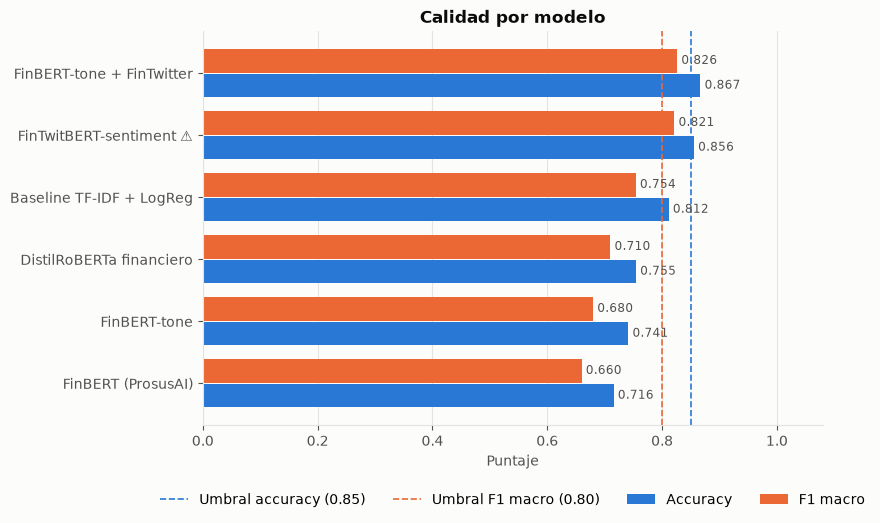

In [26]:
plot_metric_comparison(comparison);


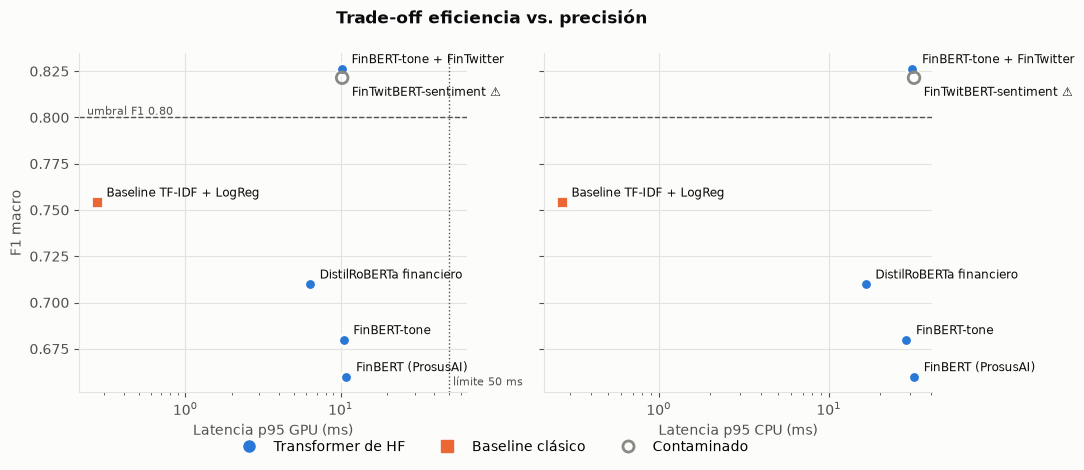

In [27]:
plot_tradeoff(comparison);


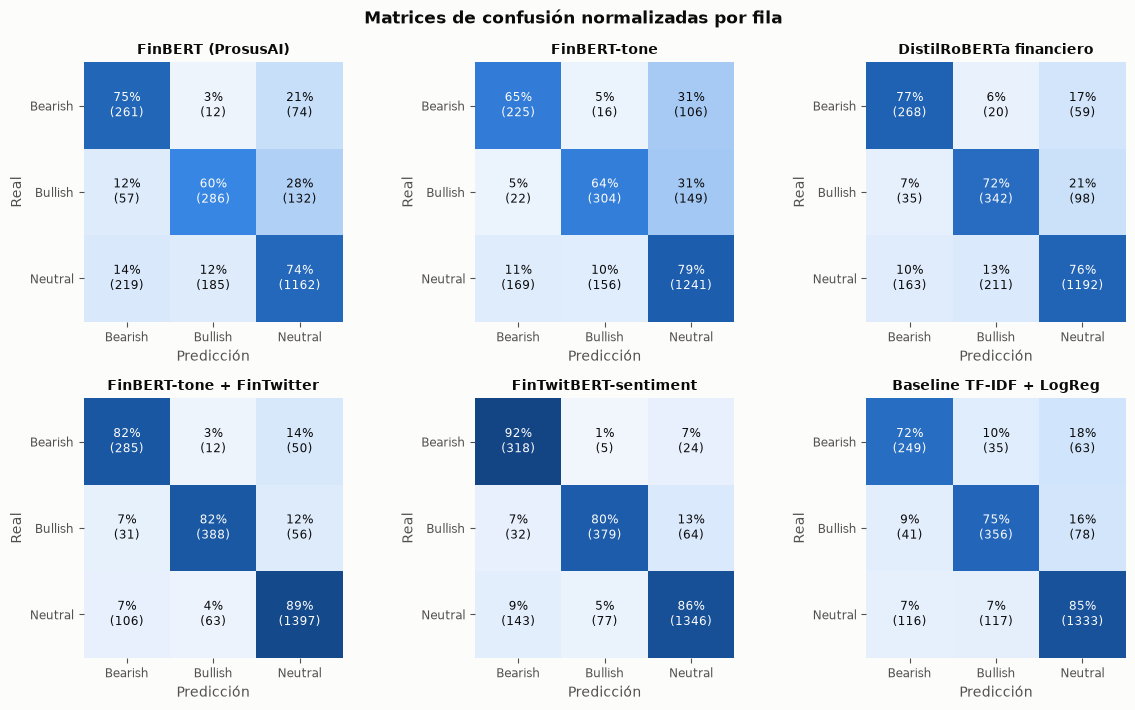

In [28]:
plot_confusion_matrices(all_results, PRIMARY_TEXT);


In [29]:
per_class = per_class_table(all_results)
per_class.pivot(index="modelo", columns="clase", values="f1").round(3)


clase,Bearish,Bullish,Neutral
modelo,,,
Baseline TF-IDF + LogReg,0.661,0.724,0.877
DistilRoBERTa financiero,0.659,0.653,0.818
FinBERT (ProsusAI),0.590,0.597,0.792
FinBERT-tone,0.590,0.639,0.811
FinBERT-tone + FinTwitter,0.741,0.827,0.910
FinTwitBERT-sentiment,0.757,0.810,0.897


### Ajuste mínimo: texto original frente a texto sin URLs

In [30]:
ablation = ablation_table(all_results)
ablation.round(4)


,modelo,accuracy (original),accuracy (sin URLs),f1_macro (original),f1_macro (sin URLs),recall_Bearish (original),recall_Bearish (sin URLs),delta_f1_macro
0,Baseline TF-IDF + LogReg,0.8111,0.8116,0.7537,0.7542,0.7205,0.7176,0.0005
1,DistilRoBERTa financiero,0.7496,0.7546,0.7063,0.7099,0.7752,0.7723,0.0036
2,FinBERT (ProsusAI),0.7253,0.7157,0.6682,0.6599,0.7608,0.7522,-0.0083
3,FinBERT-tone,0.7483,0.7412,0.6612,0.6799,0.5101,0.6484,0.0186
4,FinBERT-tone + FinTwitter,0.8656,0.8668,0.8219,0.8263,0.7695,0.8213,0.0044
5,FinTwitBERT-sentiment,0.8224,0.8555,0.7946,0.8214,0.9193,0.9164,0.0268


Quitar URLs mejora el F1 en 5 de 6 modelos y sube el recall Bearish del recomendado de 0.770 a 0.821, justo por encima del umbral.

## 10. Umbrales y recomendación

In [31]:
print("Umbrales:", THRESHOLDS)
comparison[["modelo", "contaminado", "cumple_accuracy", "cumple_f1_macro",
            "cumple_recall_bearish", "cumple_latencia", "cumple_todos", "elegible"]]


Umbrales: {'accuracy': 0.85, 'f1_macro': 0.8, 'recall_Bearish': 0.8, 'p95_latency_ms': 50.0}


,modelo,contaminado,cumple_accuracy,cumple_f1_macro,cumple_recall_bearish,cumple_latencia,cumple_todos,elegible
0,FinBERT (ProsusAI),False,False,False,False,True,False,False
1,FinBERT-tone,False,False,False,False,True,False,False
2,DistilRoBERTa financiero,False,False,False,False,True,False,False
3,FinBERT-tone + FinTwitter,False,True,True,True,True,True,True
4,FinTwitBERT-sentiment,True,True,True,True,True,True,False
5,Baseline TF-IDF + LogReg,False,False,False,False,True,False,False


In [32]:
best = recommend(comparison)
best_variant = results[best["key"]]["variants"][PRIMARY_TEXT]
confidence = confidence_coverage(eval_df["label_name"], best_variant["pred"], best_variant["score"])
print(f"Modelo recomendado: {best['model_id']}")
confidence.round(3)


Modelo recomendado: nickmuchi/finbert-tone-finetuned-fintwitter-classification


,umbral_confianza,cobertura,a_revision_humana,accuracy,f1_macro,recall_Bearish,precision_Bearish
0,0.00,1.000,0,0.867,0.826,0.821,0.675
1,0.50,0.982,44,0.874,0.835,0.836,0.690
2,0.60,0.938,148,0.886,0.850,0.845,0.728
3,0.70,0.888,268,0.904,0.873,0.869,0.767
4,0.80,0.827,413,0.926,0.898,0.887,0.810
5,0.90,0.740,622,0.951,0.931,0.916,0.871
6,0.95,0.643,852,0.972,0.961,0.948,0.944


In [33]:
save_results(all_results, comparison, ablation, per_class, eval_df, HARDWARE, confidence)
print(f"Resultados guardados en {RESULTS_DIR.relative_to(PROJECT_ROOT)}/")


Resultados guardados en results/


## 11. Conclusión

Recomendado: **`nickmuchi/finbert-tone-finetuned-fintwitter-classification`** con limpieza de URLs y
umbral de confianza de 0.70, que automatiza ≈ 89 % de los tweets y envía el resto a revisión humana.